# Extended Data Figure 4: Benefit-to-cost ratio

Run from the notebook directory. The supplied independent-initial-condition data are used by default. Set `RECOMPUTE=True` to repeat the numerical integrations. Dependencies: NumPy, pandas, SciPy, Numba, Matplotlib, and IPython.

In [1]:
from pathlib import Path
import json
import os
import time
os.environ.setdefault('NUMBA_THREADING_LAYER', 'workqueue')
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from numba import njit, prange, set_num_threads
from scipy.spatial import Delaunay
from scipy.stats import qmc
from scipy.interpolate import PchipInterpolator

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'extended_data_figure4'
FIGURES = ROOT / 'figures' / 'extended_data_figure4'
DATA.mkdir(parents=True,exist_ok=True)
FIGURES.mkdir(parents=True,exist_ok=True)
RECOMPUTE = False
E1 = E2 = .02
N_RUNS, N_INITIAL = 8, 512
SEEDS = np.arange(2026,2026+N_RUNS,dtype=int)
MAX_CHUNKS = 64
NORMS = ('SC','SH','SJ','SS')
CONDITIONS = ('No inertia','One-step','Multi-step')
DEPTHS = {'SC':(2,0),'SH':(3,0),'SJ':(4,3),'SS':(1,2)}
NAMES = {'SC':'Scoring','SH':'Shunning','SJ':'Stern Judging','SS':'Simple Standing'}
COLORS = {'No inertia':'#6B6B6B','One-step':'#0077BB','Multi-step':'#D55E00'}
NORM_PARAMETERS = {'SC':(1.,0.),'SH':(0.,0.),'SJ':(0.,1.),'SS':(1.,1.)}
RATIOS = np.unique(np.r_[1.001,np.linspace(1.1,7,31),np.linspace(7.25,10,12),5.])
SIMULATION_SETTINGS = dict(e1=E1,e2=E2,n_runs=N_RUNS,n_initial=N_INITIAL,seeds=SEEDS.tolist(),
    ratios=RATIOS.tolist(),depths={k:list(v) for k,v in DEPTHS.items()},max_chunks=MAX_CHUNKS,
    mesh_SC=41,mesh_other=25,method='all-good reputation ODE; midpoint strategy ODE; mean, individual-change and residual-q99 gates')
RAW_FILE = DATA / 'repeated_runs.csv'
SUMMARY_FILE = DATA / 'cooperation_summary.csv'
RULE_FILE = DATA / 'invasion_thresholds.csv'
SETTINGS_FILE = DATA / 'simulation_settings.json'
set_num_threads(min(4,os.cpu_count() or 1))
assert N_INITIAL & (N_INITIAL-1) == 0 and N_RUNS >= 2
assert np.all(RATIOS > 1)


## Model and numerical integration

Reputations equilibrate from all-good initial conditions before the strategy field is evaluated. Each parameter point uses eight independent scrambled Sobol samples of 512 initial strategy compositions.

In [2]:
def model_parameters(norm, condition):
    p, q = NORM_PARAMETERS[norm]
    epsilon = (1 - E1) * (1 - E2) + E1 * E2
    assessment = [epsilon, p * (epsilon - E2) + q * (1 - epsilon - E2) + E2, E2, q * (1 - 2 * E2) + E2]
    alpha = beta = 0.0 if condition == 'No inertia' else 1.0
    k1, k2 = (1, 1) if condition != 'Multi-step' else DEPTHS[norm]
    return np.array([*assessment, alpha, beta, k1, k2, E1], dtype=float)

@njit
def reputation_readout(phi, a):
    if a[4] == 0.0 and a[5] == 0.0:
        return phi
    bad_power = (1 - phi) ** int(a[6])
    good_power = phi ** int(a[7])
    return good_power * (1 - bad_power * (1 - phi)) / (bad_power + good_power - bad_power * good_power)

@njit
def reputation_rhs_scalar(x, y, z, rc, rd, rz, a):
    mean = x * rc + y * rd + z * rz
    agree = x * rc * rc + y * rd * rd + z * rz * rz
    pc = mean * a[0] + (1 - mean) * a[1]
    pd = mean * a[2] + (1 - mean) * a[3]
    pz = agree * a[0] + (mean - agree) * (a[1] + a[2]) + (1 - 2 * mean + agree) * a[3]
    return (reputation_readout(pc, a) - rc, reputation_readout(pd, a) - rd, reputation_readout(pz, a) - rz)

@njit
def no_inertia_scalar(x, y, z, a):
    pcg, pcb, pdg, pdb = a[:4]
    bc, bd = (pcg - pcb, pdg - pdb)
    denominator = 1 - x * bc - y * bd
    m0, m1 = ((x * pcb + y * pdb) / denominator, z / denominator)
    c0, c1, d0, d1 = (pcb + bc * m0, bc * m1, pdb + bd * m0, bd * m1)
    qa = (pcg - pcb - pdg + pdb) * (x * c1 * c1 + y * d1 * d1 + z)
    qb = 2 * (pcg - pcb - pdg + pdb) * (x * c0 * c1 + y * d0 * d1) + (pcb + pdg - 2 * pdb) * m1 - 1
    qc = (pcg - pcb - pdg + pdb) * (x * c0 * c0 + y * d0 * d0) + (pcb + pdg - 2 * pdb) * m0 + pdb
    rz = 2 * qc / (-qb + np.sqrt(max(0.0, qb * qb - 4 * qa * qc)))
    mean = m0 + m1 * rz
    return (pcb + bc * mean, pdb + bd * mean, rz)

@njit
def clip_probability(value):
    return min(1.0, max(0.0, value))

@njit(parallel=True)
def reputation_equilibria(f, a, baseline, tolerance=1e-10):
    r = np.empty_like(f)
    residual = np.zeros(len(f))
    for i in prange(len(f)):
        x, y, z = f[i]
        if baseline:
            r[i] = no_inertia_scalar(x, y, z, a)
            continue
        rc = rd = rz = 1.0
        for step in range(100000):
            dt = 0.1 if step < 20000 else 0.2
            k1 = reputation_rhs_scalar(x, y, z, rc, rd, rz, a)
            if max(abs(k1[0]), abs(k1[1]), abs(k1[2])) <= tolerance:
                break
            k2 = reputation_rhs_scalar(x, y, z, clip_probability(rc + 0.5 * dt * k1[0]), clip_probability(rd + 0.5 * dt * k1[1]), clip_probability(rz + 0.5 * dt * k1[2]), a)
            k3 = reputation_rhs_scalar(x, y, z, clip_probability(rc + 0.5 * dt * k2[0]), clip_probability(rd + 0.5 * dt * k2[1]), clip_probability(rz + 0.5 * dt * k2[2]), a)
            k4 = reputation_rhs_scalar(x, y, z, clip_probability(rc + dt * k3[0]), clip_probability(rd + dt * k3[1]), clip_probability(rz + dt * k3[2]), a)
            rc = clip_probability(rc + dt * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]) / 6)
            rd = clip_probability(rd + dt * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1]) / 6)
            rz = clip_probability(rz + dt * (k1[2] + 2 * k2[2] + 2 * k3[2] + k4[2]) / 6)
        r[i] = (rc, rd, rz)
        rhs = reputation_rhs_scalar(x, y, z, rc, rd, rz, a)
        residual[i] = max(abs(rhs[0]), abs(rhs[1]), abs(rhs[2]))
    return (r, residual)

def exact_observables(f, a, baseline, ratio):
    r, residual = reputation_equilibria(f, a, baseline)
    if np.max(residual) > 1e-10:
        raise RuntimeError('Reputation equilibrium did not converge.')
    mean_good = np.sum(f * r, axis=1)
    intended = f[:, 0] + f[:, 2] * mean_good
    pi = (1 - E1) * (ratio * (f[:, 0, None] + f[:, 2, None] * r) - np.column_stack((np.ones(len(f)), np.zeros(len(f)), mean_good)))
    rhs = f * (pi - np.sum(f * pi, axis=1, keepdims=True))
    rhs -= f * np.sum(rhs, axis=1, keepdims=True)
    return (intended, np.max(np.abs(rhs), axis=1))

def prepare_mesh(a, resolution):
    f = np.array([(i / resolution, j / resolution, 1 - (i + j) / resolution) for i in range(resolution + 1) for j in range(resolution + 1 - i)])
    r, residual = reputation_equilibria(f, a, False)
    if np.max(residual) > 1e-10:
        raise RuntimeError('Reputation mesh did not converge.')
    tri = Delaunay(f[:, :2])
    cells = np.full((resolution, resolution, 2), -1, dtype=np.int64)
    for index, vertices in enumerate(tri.simplices):
        i, j = np.rint(f[vertices, :2] * resolution).astype(int).min(axis=0)
        slot = 0 if cells[i, j, 0] == -1 else 1
        assert cells[i, j, slot] == -1
        cells[i, j, slot] = index
    benefits = (1 - E1) * (f[:, 0, None] + f[:, 2, None] * r)
    costs = (1 - E1) * np.column_stack((-np.ones(len(f)), np.zeros(len(f)), -np.sum(f * r, axis=1)))
    benefit_rhs = f * (benefits - np.sum(f * benefits, axis=1, keepdims=True))
    cost_rhs = f * (costs - np.sum(f * costs, axis=1, keepdims=True))
    return (cells, tri.transform.copy(), tri.simplices.copy(), benefit_rhs, cost_rhs, f)

@njit
def mesh_rhs_scalar(x, y, z, cells, transforms, simplices, values):
    m = cells.shape[0]
    i, j = (min(int(x * m), m - 1), min(int(y * m), m - 1))
    if i + j >= m:
        if i > 0:
            i -= 1
        else:
            j -= 1
    for slot in range(2):
        index = cells[i, j, slot]
        if index < 0:
            continue
        t = transforms[index]
        u = t[0, 0] * (x - t[2, 0]) + t[0, 1] * (y - t[2, 1])
        v = t[1, 0] * (x - t[2, 0]) + t[1, 1] * (y - t[2, 1])
        if min(u, v, 1 - u - v) >= -1e-10:
            vertices = simplices[index]
            dx = u * values[vertices[0], 0] + v * values[vertices[1], 0] + (1 - u - v) * values[vertices[2], 0]
            dy = u * values[vertices[0], 1] + v * values[vertices[1], 1] + (1 - u - v) * values[vertices[2], 1]
            dz = -dx - dy
            dx, dy, dz = (0.0 if x <= 1e-12 else dx, 0.0 if y <= 1e-12 else dy, 0.0 if z <= 1e-12 else dz)
            total = dx + dy + dz
            return (dx - x * total, dy - y * total, dz - z * total)
    raise ValueError('Point outside the strategy triangulation.')

@njit
def strategy_rhs_scalar(x, y, z, a, baseline, ratio, cells, transforms, simplices, values):
    if not baseline:
        return mesh_rhs_scalar(x, y, z, cells, transforms, simplices, values)
    rc, rd, rz = no_inertia_scalar(x, y, z, a)
    mean_good = x * rc + y * rd + z * rz
    pc = (1 - a[8]) * (ratio * (x + z * rc) - 1)
    pd = (1 - a[8]) * ratio * (x + z * rd)
    pz = (1 - a[8]) * (ratio * (x + z * rz) - mean_good)
    mean = x * pc + y * pd + z * pz
    dx, dy, dz = (x * (pc - mean), y * (pd - mean), z * (pz - mean))
    total = dx + dy + dz
    return (dx - x * total, dy - y * total, dz - z * total)

@njit
def normalize_scalar(x, y, z):
    x, y, z = (max(0.0, x), max(0.0, y), max(0.0, z))
    total = x + y + z
    return (x / total, y / total, z / total)

@njit(parallel=True)
def integrate_chunk(f, a, baseline, ratio, cells, transforms, simplices, values, dt, steps):
    result = f.copy()
    for i in prange(len(f)):
        x, y, z = f[i]
        for _ in range(steps):
            k1 = strategy_rhs_scalar(x, y, z, a, baseline, ratio, cells, transforms, simplices, values)
            if not baseline and max(abs(k1[0]), abs(k1[1]), abs(k1[2])) <= 5e-07:
                break
            mid = normalize_scalar(x + 0.5 * dt * k1[0], y + 0.5 * dt * k1[1], z + 0.5 * dt * k1[2])
            k2 = strategy_rhs_scalar(*mid, a, baseline, ratio, cells, transforms, simplices, values)
            x, y, z = normalize_scalar(x + dt * k2[0], y + dt * k2[1], z + dt * k2[2])
        result[i] = (x, y, z)
    return result

def initial_compositions(seed):
    uv = qmc.Sobol(2, scramble=True, seed=int(seed)).random_base2(int(np.log2(N_INITIAL)))
    reflected = uv.sum(axis=1) > 1
    uv[reflected] = 1 - uv[reflected]
    return np.column_stack((uv, 1 - uv.sum(axis=1)))

def simulate_repeats(norm, condition, ratio, initial, mesh):
    a = model_parameters(norm, condition)
    baseline = condition == 'No inertia'
    dt, chunk_steps = (0.05, 5000) if norm == 'SC' else (0.1, 4000)
    mean_tol, individual_tol, residual_tol = (2e-06, 2e-05, 2e-05) if baseline else (2e-05, 0.0001, 0.002)
    if norm == 'SC' and (not baseline):
        mean_tol, individual_tol = (5e-05, 0.0002)
    checks_required = 3 if baseline else 2
    cells, transforms, simplices, benefit_rhs, cost_rhs, _ = mesh
    values = ratio * benefit_rhs + cost_rhs
    f = initial.copy()
    previous, _ = exact_observables(f, a, baseline, ratio)
    consecutive = np.zeros(N_RUNS, dtype=int)
    for chunk in range(MAX_CHUNKS):
        f = integrate_chunk(f, a, baseline, ratio, cells, transforms, simplices, values, dt, chunk_steps)
        intended, residual = exact_observables(f, a, baseline, ratio)
        difference = (intended - previous).reshape(N_RUNS, N_INITIAL)
        mean_change = np.abs(difference.mean(axis=1))
        individual_change = np.abs(difference).mean(axis=1)
        q99 = np.quantile(residual.reshape(N_RUNS, N_INITIAL), 0.99, axis=1)
        stable = (mean_change <= mean_tol) & (individual_change <= individual_tol) & (q99 <= residual_tol)
        consecutive = np.where(stable, consecutive + 1, 0)
        previous = intended
        if np.all(consecutive >= checks_required):
            break
    else:
        raise RuntimeError(f'{norm}/{condition}/R={ratio:g}: observable stability failed; increase MAX_CHUNKS before averaging or plotting.')
    return [dict(norm=norm, condition=condition, b_over_c=float(ratio), run=run + 1, seed=int(SEEDS[run]), n_initial=N_INITIAL, intended_cooperation=float(intended.reshape(N_RUNS, N_INITIAL)[run].mean()), mean_change=float(mean_change[run]), individual_change=float(individual_change[run]), residual_q99=float(q99[run]), max_strategy_residual=float(residual.reshape(N_RUNS, N_INITIAL)[run].max()), observable_stable=True, strategy_steps=(chunk + 1) * chunk_steps, mesh_resolution=0 if baseline else cells.shape[0]) for run in range(N_RUNS)]

def generate_repeated_data():
    initial = np.vstack([initial_compositions(seed) for seed in SEEDS])
    rows = []
    for norm in NORMS:
        for condition in CONDITIONS:
            start = time.perf_counter()
            if condition == 'No inertia':
                mesh = (np.zeros((1, 1, 2), dtype=np.int64), np.zeros((1, 3, 2)), np.zeros((1, 3), dtype=np.int64), np.zeros((1, 3)), np.zeros((1, 3)), np.zeros((1, 3)))
            else:
                mesh = prepare_mesh(model_parameters(norm, condition), 41 if norm == 'SC' else 25)
            for index, ratio in enumerate(RATIOS):
                rows.extend(simulate_repeats(norm, condition, ratio, initial, mesh))
                if index == 0 or (index + 1) % 10 == 0 or index == len(RATIOS) - 1:
                    print(f'{norm:2s} | {condition:10s} | {index + 1}/{len(RATIOS)} ratios | {time.perf_counter() - start:.1f} s', flush=True)
    return pd.DataFrame(rows)

def average_runs(raw):
    keys = ['norm', 'condition', 'b_over_c']
    counts = raw.groupby(keys)['run'].nunique()
    assert (counts == N_RUNS).all() and (not raw.duplicated(keys + ['run']).any())
    summary = raw.groupby(keys, sort=False)['intended_cooperation'].agg(mean='mean', sd='std', n_runs='size').reset_index()
    summary['sem'] = summary['sd'] / np.sqrt(summary['n_runs'])
    return summary

def invasion_thresholds():
    rows = []
    for norm in NORMS:
        for condition in CONDITIONS:
            a = model_parameters(norm, condition)
            r, residual = reputation_equilibria(np.array([[0.0, 0.0, 1.0]]), a, condition == 'No inertia', tolerance=1e-13)
            assert residual[0] <= 1e-13
            gc, gd, g = r[0]
            if condition == 'No inertia':
                assert abs(g - g * gc - (1 - g) * gd) < 1e-12
                lower = upper = 1 / (gc - gd) if gc - gd > 1e-12 else np.inf
            else:
                lower = g / (g - gd) if g - gd > 1e-12 else np.inf
                upper = (1 - g) / (gc - g) if gc - g > 1e-12 else np.inf
            rows.append(dict(norm=norm, condition=condition, R_L=lower, R_U=upper, g_ALLC=gc, g_ALLD=gd, g_DISC=g, alpha=a[4], beta=a[5], k1=int(a[6]), k2=int(a[7])))
    return pd.DataFrame(rows)

## Repeated means and uncertainty

The ordinate is intended cooperation. The standard error is calculated across the eight run means. Solid segments indicate local pure-DISC protection against rare ALLC and ALLD; this differs from the global cooperation average.

In [3]:
if RECOMPUTE:
    raw_runs = generate_repeated_data()
    rules = invasion_thresholds()
    raw_runs.to_csv(RAW_FILE,index=False)
    rules.to_csv(RULE_FILE,index=False)
    SETTINGS_FILE.write_text(json.dumps(SIMULATION_SETTINGS,indent=2)+'\n')
else:
    if not all(p.is_file() for p in (RAW_FILE,RULE_FILE,SETTINGS_FILE)):
        raise FileNotFoundError('Supply data/extended_data_figure4 or set RECOMPUTE=True.')
    if json.loads(SETTINGS_FILE.read_text()) != SIMULATION_SETTINGS:
        raise ValueError('The saved simulation configuration differs from the requested parameters.')
    raw_runs = pd.read_csv(RAW_FILE)
    rules = pd.read_csv(RULE_FILE)
assert raw_runs.observable_stable.all()
assert raw_runs.intended_cooperation.between(0,1).all()
assert set(raw_runs.seed) == set(SEEDS) and (raw_runs.n_initial == N_INITIAL).all()
assert len(raw_runs) == len(NORMS)*len(CONDITIONS)*len(RATIOS)*N_RUNS
assert len(rules) == len(NORMS)*len(CONDITIONS)
assert not rules.duplicated(['norm','condition']).any()
summary = average_runs(raw_runs)
assert len(summary) == len(NORMS)*len(CONDITIONS)*len(RATIOS)
summary.to_csv(SUMMARY_FILE,index=False)
validation = dict(raw_rows=len(raw_runs),summary_rows=len(summary),invasion_rules=len(rules),
    all_saved_observable_stability_gates_passed=bool(raw_runs.observable_stable.all()),
    statistics_recomputed=True,full_strategy_integrations_rerun=RECOMPUTE,
    cooperation_measure='intended',uncertainty='SEM of eight independent run means')
(DATA/'output_validation.json').write_text(json.dumps(validation,indent=2)+'\n')
thresholds = rules.set_index(['norm','condition'])
print(f'Analyzed {len(raw_runs)} replicate means and saved {len(summary)} mean/SEM rows.')


Analyzed 4320 replicate means and saved 540 mean/SEM rows.


In [4]:
def panel_curve(norm, condition):
    rows = summary[(summary.norm == norm) & (summary.condition == condition)].sort_values('b_over_c')
    x, mean, sem = (rows[key].to_numpy() for key in ('b_over_c', 'mean', 'sem'))
    with np.errstate(over='ignore'):
        interpolant = PchipInterpolator(x, mean, extrapolate=False)
    assert np.max(np.abs(interpolant(x) - mean)) < 1e-12
    return (x, mean, sem, interpolant)

def draw_panel(ax, norm, labelled):
    ax.axvline(5, color='#929292', lw=0.55, ls=(0, (3, 3)), zorder=0)
    for condition in CONDITIONS:
        color = COLORS[condition]
        t = thresholds.loc[norm, condition]
        x, mean, sem, curve = panel_curve(norm, condition)
        boundaries = [v for v in (t.R_L, t.R_U) if x[0] <= v <= x[-1]]
        grid = np.unique(np.r_[np.linspace(x[0], x[-1], 1800), x, boundaries])
        y = curve(grid)
        spread = np.interp(grid, x, sem)
        ax.fill_between(grid, np.maximum(0, y - spread), np.minimum(1, y + spread), color=color, alpha=0.1, lw=0, zorder=1)
        cuts = np.unique(np.r_[x[0], boundaries, x[-1]])
        for start, stop in zip(cuts[:-1], cuts[1:]):
            segment = np.r_[start, grid[(grid > start) & (grid < stop)], stop]
            protected = t.R_L < (start + stop) / 2 < t.R_U
            ax.plot(segment, curve(segment), color=color, lw=LINEWIDTHS[condition], ls='-' if protected else (0, (3, 2)), solid_capstyle='butt', dash_capstyle='butt', zorder=3 if protected else 2)
        left, right = (max(x[0], t.R_L), min(x[-1], t.R_U))
        if left < right and t.R_U > 10:
            ax.plot(10, curve(10), marker='>', linestyle='none', color=color, ms=3.2, zorder=5, clip_on=False)
        if labelled and t.R_L < t.R_U and (x[0] < t.R_U < 10):
            offset = (5, 10) if condition == 'One-step' else (-5, 11)
            ax.annotate('$R_U$=' + f'{t.R_U:.2f}', (t.R_U, curve(t.R_U)), xytext=offset, textcoords='offset points', fontsize=6, ha='left' if offset[0] > 0 else 'right', color='#333333', arrowprops={'arrowstyle': '-', 'color': color, 'lw': 0.4})
    ax.set(xlim=(0.7, 10), ylim=(-0.03, 1.025), xticks=[1, 3, 5, 7, 10], yticks=[0, 0.5, 1])
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='both', bottom=True, left=True, top=False, right=False, direction='out', length=2.2, width=0.5, pad=3)
    if labelled:
        t = thresholds.loc[norm, 'No inertia']
        if 1 < t.R_L == t.R_U < 10:
            curve = panel_curve(norm, 'No inertia')[-1]
            ax.annotate('$R_L=R_U$=' + f'{t.R_L:.2f}', (t.R_L, curve(t.R_L)), xytext=(2.35, 0.105), textcoords='data', fontsize=5.7, color='#555555', arrowprops={'arrowstyle': '-', 'lw': 0.4, 'color': '#6B6B6B'})
    else:
        ax.tick_params(labelbottom=False, labelleft=False, labeltop=False, labelright=False)
        ax.set_facecolor('none')

LINEWIDTHS = {'No inertia':.9,'One-step':1.2,'Multi-step':1.5}
mpl.rcParams.update({'font.family':'DejaVu Sans','font.size':8,'axes.labelsize':8,
    'axes.titlesize':9,'xtick.labelsize':8,'ytick.labelsize':8,'axes.linewidth':.6,
    'legend.fontsize':8,'legend.frameon':False,'pdf.fonttype':42,'svg.fonttype':'none'})


def save_figure(fig,name):
    for extension in ('pdf','svg'):
        fig.savefig(FIGURES / f'{name}.{extension}',bbox_inches='tight',pad_inches=.04,facecolor='white')


def plot_panel(norm):
    fig,ax = plt.subplots(figsize=(4.1,3.0))
    fig.subplots_adjust(left=.18,right=.97,bottom=.23,top=.88)
    draw_panel(ax,norm,labelled=True)
    ax.set(title=NAMES[norm],xlabel=r'Benefit-to-cost ratio, $b/c$',ylabel='Intended cooperation')
    return fig


def plot_combined():
    fig,axes = plt.subplots(2,2,sharex=True,sharey=True,figsize=(9.8,6.3))
    fig.subplots_adjust(left=.11,right=.985,bottom=.16,top=.80,wspace=.23,hspace=.42)
    for index,(norm,ax) in enumerate(zip(NORMS,axes.flat)):
        draw_panel(ax,norm,labelled=True)
        ax.set_title(NAMES[norm],loc='left',pad=6)
        ax.text(-.065,1.065,'abcd'[index],transform=ax.transAxes,fontsize=11,fontweight='bold',ha='right')
    handles=[Line2D([],[],color=COLORS[condition],lw=LINEWIDTHS[condition],ls=style,
        label=f'{condition} ({state})') for style,state in [('-','Protected'),((0,(3,2)),'Unprotected')]
        for condition in CONDITIONS]
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.54,.995),ncol=2,
        handlelength=3,columnspacing=2.5,labelspacing=.7,frameon=False)
    fig.supylabel('Basin-weighted intended cooperation',x=.025,y=.48)
    fig.supxlabel(r'Benefit-to-cost ratio, $b/c$',x=.55,y=.07)
    fig.text(.55,.018,r'Solid: protected | Dashed: unprotected | Arrow: $R_U>10$ | Shading: $\pm$ s.e.m.',
        ha='center',fontsize=7,color='#555555')
    return fig


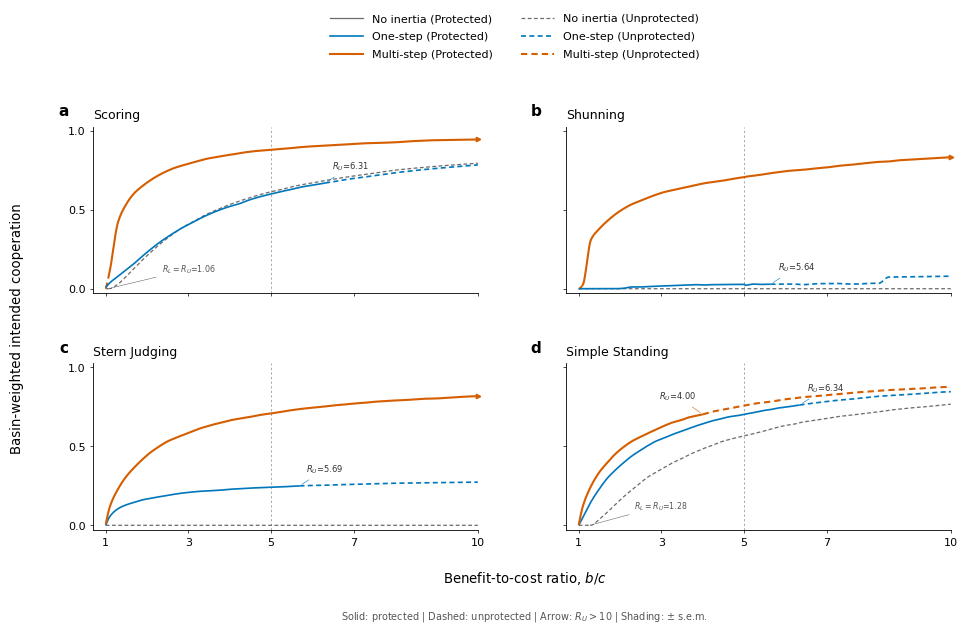

Saved four panels and one combined figure in PDF and SVG.


In [5]:
for norm in NORMS:
    fig = plot_panel(norm)
    save_figure(fig,f'panel_{norm}')
    plt.close(fig)
fig = plot_combined()
save_figure(fig,'Extended_Data_Figure4_combined')
plt.show()
plt.close(fig)
assert len(list(FIGURES.glob('*.pdf'))) == len(list(FIGURES.glob('*.svg'))) == 5
print('Saved four panels and one combined figure in PDF and SVG.')
